In [1]:
!pip -q install -U transformers datasets peft accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [5]:

import torch
import transformers
import datasets
import peft
import accelerate

print("Setup successful!")
print("GPU available:", torch.cuda.is_available())


Setup successful!
GPU available: True


In [3]:

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "HuggingFaceTB/SmolLM2-135M-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float32
).to("cuda")

print("Model loaded successfully!")


config.json:   0%|          | 0.00/861 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.76k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Model loaded successfully!


In [7]:

# Test the original model before fine-tuning

test_questions = [
    "What is customer retention?",
    "What is a value proposition?",
    "Why is market segmentation important?",
    "What is a competitive advantage?"
]

def get_response(question):
    messages = [
        {"role": "user", "content": question}
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    )

    # Extract input IDs as a tensor
    if hasattr(inputs, "input_ids"):
        inputs = inputs["input_ids"]

    inputs = inputs.to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            input_ids=inputs,
            max_new_tokens=180,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    response = tokenizer.decode(
        outputs[0][inputs.shape[-1]:],
        skip_special_tokens=True
    )

    return response.strip()

before_results = {}

for question in test_questions:
    answer = get_response(question)
    before_results[question] = answer

    print("\nQUESTION:", question)
    print("BEFORE FINE-TUNING:")
    print(answer)
    print("-" * 60)



QUESTION: What is customer retention?
BEFORE FINE-TUNING:
Customer retention refers to the ability of a business to retain customers over time, often through various channels such as loyalty programs, social media, email marketing, and in-store experiences. It involves building a strong emotional connection with customers, fostering loyalty, and encouraging repeat business.

Effective customer retention strategies can lead to increased customer satisfaction, loyalty, and ultimately, revenue growth. By retaining customers, businesses can:

* Increase customer lifetime value (CLV) by retaining customers for a longer period
* Reduce churn rates and improve customer retention rates
* Enhance customer loyalty and retention through personalized experiences and rewards
* Drive revenue growth through repeat business and positive word-of-mouth

Some common customer retention strategies include:

* Loyalty programs that reward repeat customers
* Social media campaigns that encourage customer en

In [9]:

import json

with open("before_results.json", "w", encoding="utf-8") as f:
    json.dump(before_results, f, indent=2, ensure_ascii=False)

print("Before-training results saved successfully!")
print("Number of saved answers:", len(before_results))



Before-training results saved successfully!
Number of saved answers: 4


In [10]:

import json

# Option A: Business Concepts Tutor
# 24 training examples with the required four-part format

examples = [
    (
        "What is customer churn?",
        "The percentage of customers who stop using a business during a given period.",
        "A streaming service loses 50 out of 1,000 subscribers in one month, giving a 5% churn rate.",
        "It helps businesses measure customer losses and improve retention.",
        "Confusing churn rate with the number of new customers."
    ),
    (
        "Explain customer retention.",
        "A business's ability to keep existing customers over time.",
        "A gym offers membership rewards to encourage renewals.",
        "Retaining customers can support stable revenue and reduce acquisition costs.",
        "Assuming all repeat customers are loyal."
    ),
    (
        "What does market segmentation mean?",
        "Dividing a broad market into smaller groups with similar needs or characteristics.",
        "A clothing company targets students and professionals with different collections.",
        "It helps businesses tailor products and marketing to specific customers.",
        "Assuming every customer has the same needs."
    ),
    (
        "Define target market.",
        "The specific group of customers a business aims to serve.",
        "A toy company focuses on parents of young children.",
        "It helps businesses direct marketing resources effectively.",
        "Trying to appeal equally to everyone."
    ),
    (
        "Can you explain a value proposition?",
        "The main benefit a business promises to deliver to customers.",
        "A delivery company promises reliable next-day shipping.",
        "It explains why customers should choose a product or service.",
        "Listing product features without explaining customer benefits."
    ),
    (
        "What is competitive advantage?",
        "A strength that helps a business perform better than competitors.",
        "A retailer delivers orders faster than competing stores.",
        "It helps a company attract customers and defend its market position.",
        "Assuming a competitive advantage lasts forever."
    ),
    (
        "What does brand awareness mean?",
        "The extent to which customers recognize or remember a brand.",
        "Shoppers recognize a company's logo on a store shelf.",
        "It helps a brand become familiar to potential customers.",
        "Assuming brand recognition automatically produces sales."
    ),
    (
        "Explain brand loyalty.",
        "A customer's preference for repeatedly choosing a particular brand.",
        "A runner consistently buys shoes from the same company.",
        "It can encourage repeat purchases and recommendations.",
        "Confusing brand loyalty with brand awareness."
    ),
    (
        "Define profit margin.",
        "The percentage of revenue remaining as profit after relevant expenses.",
        "A company earns $20 in net profit from $100 in sales, producing a 20% net profit margin.",
        "It helps businesses evaluate profitability.",
        "Confusing total revenue with profit."
    ),
    (
        "What is business revenue?",
        "The money a business earns from selling goods or services before deducting expenses.",
        "A bakery earns $2,000 from selling bread in one day.",
        "It helps measure sales activity and business growth.",
        "Assuming revenue is the same as profit."
    ),
    (
        "Explain fixed costs.",
        "Expenses that remain constant within a relevant range of business activity.",
        "A store pays $1,500 in monthly rent regardless of its sales volume.",
        "They help businesses plan budgets and calculate break-even points.",
        "Assuming fixed costs can never change."
    ),
    (
        "What are variable costs?",
        "Expenses that change with the level of production or sales.",
        "A bakery buys more flour when it produces more bread.",
        "They help businesses estimate production costs and pricing.",
        "Confusing variable costs with fixed costs."
    ),
    (
        "What is the break-even point?",
        "The sales level where total revenue equals total costs.",
        "A cafe covers all its costs after selling 2,000 drinks in a month.",
        "It shows the minimum sales needed to avoid a loss.",
        "Thinking break-even means earning a profit."
    ),
    (
        "Can you define cash flow?",
        "The movement of money into and out of a business.",
        "A company receives customer payments and pays its suppliers.",
        "It helps businesses manage liquidity and pay bills on time.",
        "Assuming profitable businesses always have positive cash flow."
    ),
    (
        "Explain return on investment.",
        "A measure of investment gain or loss relative to its cost.",
        "A $1,000 investment produces a $200 net gain, resulting in a 20% ROI.",
        "It helps compare the performance of investments.",
        "Ignoring investment costs when calculating returns."
    ),
    (
        "What does customer acquisition cost mean?",
        "The average cost a business incurs to gain one new customer.",
        "A business spends $500 on customer acquisition and gains 10 customers, giving a $50 CAC.",
        "It helps evaluate the efficiency of customer acquisition efforts.",
        "Ignoring acquisition expenses beyond advertising."
    ),
    (
        "Define customer lifetime value.",
        "The estimated economic value a customer contributes throughout the business relationship.",
        "A subscription company estimates that a customer will generate $600 in revenue over three years.",
        "It helps guide decisions about acquisition and retention spending.",
        "Confusing lifetime customer revenue with lifetime customer profit."
    ),
    (
        "What is SWOT analysis?",
        "A framework for examining strengths, weaknesses, opportunities, and threats.",
        "A restaurant reviews its strong reputation, limited seating, delivery opportunities, and new competitors.",
        "It helps businesses evaluate their position and plan strategies.",
        "Confusing internal weaknesses with external threats."
    ),
    (
        "Explain economies of scale.",
        "Cost advantages that occur when average production costs decrease as output increases.",
        "A factory spreads equipment costs across more units as production expands.",
        "They can improve efficiency and price competitiveness.",
        "Assuming larger production always lowers average costs."
    ),
    (
        "What is a supply chain?",
        "The network of activities and organizations involved in producing and delivering goods or services.",
        "A clothing company sources fabric, manufactures shirts, and ships them to stores.",
        "It affects costs, product availability, and delivery reliability.",
        "Thinking supply chains only involve transportation."
    ),
    (
        "Define inventory turnover.",
        "A measure of how many times average inventory is sold during a period.",
        "A store with $20,000 in annual cost of goods sold and $5,000 in average inventory has a turnover of four.",
        "It helps evaluate inventory efficiency.",
        "Assuming higher turnover is always better."
    ),
    (
        "Explain the marketing mix.",
        "The combination of product, price, place, and promotion decisions used in marketing.",
        "A cafe decides its menu, prices, store location, and advertising.",
        "It helps coordinate decisions that support marketing goals.",
        "Thinking marketing only involves advertising."
    ),
    (
        "What is a business model?",
        "The way a business creates, delivers, and captures value.",
        "A software company sells access to its platform through monthly subscriptions.",
        "It explains how the business operates and generates revenue.",
        "Confusing a business model with a business plan."
    ),
    (
        "Who are business stakeholders?",
        "People or groups that can affect or be affected by a business.",
        "Employees, customers, suppliers, and investors are stakeholders.",
        "Their interests can influence business decisions.",
        "Assuming stakeholders are only shareholders."
    )
]

training_data = []

for question, definition, example, importance, mistake in examples:
    answer = (
        f"Definition: {definition}\n"
        f"Example: {example}\n"
        f"Why it matters: {importance}\n"
        f"Common mistake: {mistake}"
    )

    training_data.append({
        "question": question,
        "answer": answer
    })

# Save the dataset
with open("training_data.json", "w", encoding="utf-8") as f:
    json.dump(training_data, f, indent=2, ensure_ascii=False)

# Verify dataset
required_headings = [
    "Definition:",
    "Example:",
    "Why it matters:",
    "Common mistake:"
]

assert len(training_data) >= 20

for item in training_data:
    assert all(
        heading in item["answer"]
        for heading in required_headings
    )

print("Dataset created successfully!")
print("Total training examples:", len(training_data))
print("\nFirst example:")
print(json.dumps(training_data[0], indent=2))


Dataset created successfully!
Total training examples: 24

First example:
{
  "question": "What is customer churn?",
  "answer": "Definition: The percentage of customers who stop using a business during a given period.\nExample: A streaming service loses 50 out of 1,000 subscribers in one month, giving a 5% churn rate.\nWhy it matters: It helps businesses measure customer losses and improve retention.\nCommon mistake: Confusing churn rate with the number of new customers."
}


In [11]:

from datasets import Dataset

# Load our saved training dataset
with open("training_data.json", "r", encoding="utf-8") as f:
    training_data = json.load(f)

# Convert question-answer pairs into chat conversations
def format_example(example):
    messages = [
        {"role": "user", "content": example["question"]},
        {"role": "assistant", "content": example["answer"]}
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )

    return {"text": text}

dataset = Dataset.from_list(training_data)
formatted_dataset = dataset.map(format_example)

print("Dataset prepared for fine-tuning!")
print("Number of examples:", len(formatted_dataset))
print("\nFirst formatted example:")
print(formatted_dataset[0]["text"])


Map:   0%|          | 0/24 [00:00<?, ? examples/s]

Dataset prepared for fine-tuning!
Number of examples: 24

First formatted example:
<|im_start|>system
You are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>
<|im_start|>user
What is customer churn?<|im_end|>
<|im_start|>assistant
Definition: The percentage of customers who stop using a business during a given period.
Example: A streaming service loses 50 out of 1,000 subscribers in one month, giving a 5% churn rate.
Why it matters: It helps businesses measure customer losses and improve retention.
Common mistake: Confusing churn rate with the number of new customers.<|im_end|>



In [14]:

from peft import LoraConfig, get_peft_model

# Configure LoRA
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

# Attach LoRA adapters to the original model
model = get_peft_model(model, lora_config)

# Display the number of trainable parameters
model.print_trainable_parameters()


trainable params: 460,800 || all params: 134,975,808 || trainable%: 0.3414


In [13]:

%pip uninstall -y torchao


Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [15]:

# Tokenize the 24 training examples

tokenizer.pad_token = tokenizer.eos_token

def tokenize_example(example):
    tokens = tokenizer(
        example["text"],
        truncation=True,
        max_length=512,
        padding="max_length"
    )

    tokens["labels"] = [
        token if mask == 1 else -100
        for token, mask in zip(
            tokens["input_ids"],
            tokens["attention_mask"]
        )
    ]

    return tokens

tokenized_dataset = formatted_dataset.map(
    tokenize_example,
    remove_columns=formatted_dataset.column_names
)

print("Tokenization successful!")
print("Total tokenized examples:", len(tokenized_dataset))
print("Tokens in first example:", len(tokenized_dataset[0]["input_ids"]))


Map:   0%|          | 0/24 [00:00<?, ? examples/s]

Tokenization successful!
Total tokenized examples: 24
Tokens in first example: 512


In [16]:

from transformers import Trainer, TrainingArguments, default_data_collator

training_args = TrainingArguments(
    output_dir="./business_tutor_lora",
    num_train_epochs=5,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=2,
    learning_rate=0.0002,
    logging_steps=5,
    save_strategy="epoch",
    save_total_limit=2,
    fp16=True,
    report_to="none",
    seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset,
    data_collator=default_data_collator
)

print("Training configuration successful!")


Training configuration successful!


In [17]:

# Run LoRA fine-tuning

train_result = trainer.train()

# Record actual training results
print("LoRA fine-tuning completed!")
print("Final training loss:", train_result.training_loss)
print("Training runtime (seconds):", train_result.metrics["train_runtime"])
print("Training steps:", train_result.global_step)


Step,Training Loss
5,3.343101
10,3.217469
15,3.090570
20,2.962746
25,2.999672
30,2.868403


LoRA fine-tuning completed!
Final training loss: 3.0803266843159993
Training runtime (seconds): 10.7692
Training steps: 30


In [18]:

import json

# Save the trained LoRA adapters
model.save_pretrained("./business_tutor_lora_final")
tokenizer.save_pretrained("./business_tutor_lora_final")

# Save actual training metrics
training_results = {
    "metrics": train_result.metrics,
    "log_history": trainer.state.log_history,
    "training_steps": train_result.global_step
}

with open("training_results.json", "w", encoding="utf-8") as f:
    json.dump(training_results, f, indent=2, default=str)

print("Trained LoRA adapters saved!")
print("Training results saved!")


Trained LoRA adapters saved!
Training results saved!


In [19]:

# Test the fine-tuned model

model.eval()

after_results = {}

for question in test_questions:
    answer = get_response(question)
    after_results[question] = answer

    print("\nQUESTION:", question)
    print("AFTER FINE-TUNING:")
    print(answer)
    print("-" * 60)



QUESTION: What is customer retention?
AFTER FINE-TUNING:
Customer retention refers to the ability of a business to retain customers over time, often through various channels such as loyalty programs, social media, email marketing, and in-store experiences. It's about building a loyal customer base that continues to purchase from the business, even after the initial investment has been made.

In essence, customer retention is about creating a sense of loyalty and satisfaction that keeps customers coming back for more. This can be achieved through various strategies, such as personalized communication, timely updates, and a positive brand experience.

For example, a company might offer a loyalty program that rewards customers for repeat purchases, or a social media campaign that encourages customers to share their experiences with friends and family. These efforts can help build a strong connection with customers and keep them coming back for more.

However, it's worth noting that custo

In [21]:

import json

with open("after_results.json", "w", encoding="utf-8") as f:
    json.dump(after_results, f, indent=2, ensure_ascii=False)

print("After-training results saved!")
print("Number of saved answers:", len(after_results))


After-training results saved!
Number of saved answers: 4



## Before-and-After Fine-Tuning Comparison

The original SmolLM2-135M-Instruct model and the LoRA fine-tuned model were tested using the same four business questions. The purpose was to determine whether fine-tuning improved the model's ability to explain business concepts using four required sections: Definition, Example, Why it matters, and Common mistake.

| Test Question | Before Fine-Tuning | After Fine-Tuning | Observation |
|---|---|---|---|
| What is customer retention? | Explained customer retention and customer loyalty strategies. | Explained customer retention with practical examples. | Both responses were relevant, but neither used the four required headings. |
| What is a value proposition? | Explained the concept and its key elements. | Explained the benefits and value offered to customers. | The explanation changed, but the required headings were still missing. |
| Why is market segmentation important? | Explained why segmentation matters and provided examples. | Explained targeted marketing with a clothing retailer example. | Both responses were relevant, but neither followed the required structure. |
| What is a competitive advantage? | Defined the concept and provided examples. | Defined the concept but included repeated phrases. | The fine-tuned response showed repetition and did not follow the required format. |

### Format Accuracy

- Before fine-tuning: 0 out of 4 responses followed the required format (0%).
- After fine-tuning: 0 out of 4 responses followed the required format (0%).

The fine-tuned model did not consistently produce the four required sections. Although the wording of the responses changed, there was no measurable improvement in format accuracy on these four questions.



## Evaluation and Discussion of Results

### Training Configuration

- Base model: HuggingFaceTB/SmolLM2-135M-Instruct
- Fine-tuning method: LoRA (Low-Rank Adaptation)
- Training dataset: 24 business concept examples
- Number of epochs: 5
- Learning rate: 0.0002
- LoRA rank: 8
- LoRA alpha: 16
- Total training steps: 30
- Training runtime: 10.7692 seconds
- Overall training loss: 3.0803

### Training Loss Analysis

The logged training loss generally decreased during fine-tuning:

- Step 5: 3.343101
- Step 10: 3.217469
- Step 15: 3.090570
- Step 20: 2.962746
- Step 25: 2.999672
- Step 30: 2.868403

The overall downward trend suggests that the model was learning patterns from the training examples. However, the decrease in training loss did not result in successful use of the required answer format.

### Response Quality Evaluation

**Format compliance:** None of the four fine-tuned responses included all four required headings: Definition, Example, Why it matters, and Common mistake.

**Relevance:** The fine-tuned model continued to provide generally relevant explanations of the business concepts.

**Clarity:** Several responses were understandable and included examples. However, some responses were lengthy or incomplete because generation was limited to 180 new tokens.

**Repetition:** The response about competitive advantage repeated similar phrases, which reduced its quality.

### Limitations

One limitation was the small training dataset of only 24 examples. This may not have provided enough varied demonstrations for the model to reliably learn the required structure.

Another limitation was the small size of the base model, which may have affected its ability to follow a specialized response format after limited fine-tuning.

The evaluation also included only four questions, so the findings cannot establish how the model would perform across a larger set of business concepts.

### Conclusion

LoRA fine-tuning was completed successfully, and training loss generally decreased. However, the fine-tuned model did not achieve the main goal of consistently answering business questions using the four required sections.

The experiment demonstrates that a lower training loss does not necessarily guarantee better performance on a specific task. Future improvements could include a larger and more varied training dataset, adjustments to training settings, and testing on additional unseen business concepts.


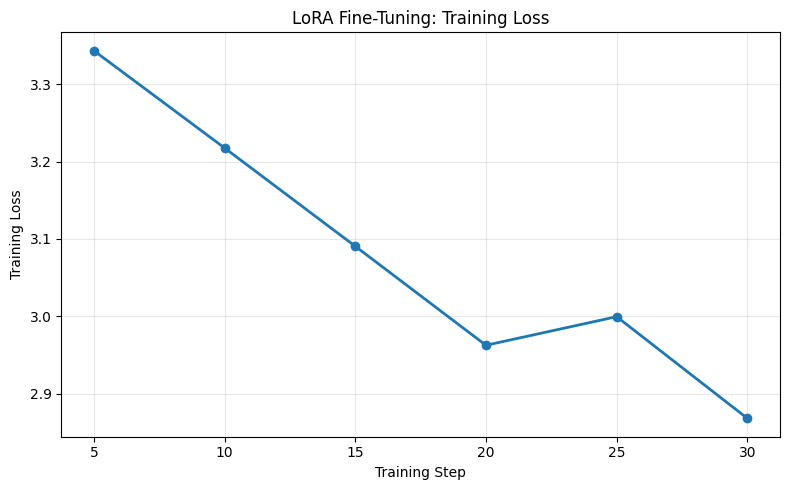

In [22]:

import matplotlib.pyplot as plt

# Actual training loss values
steps = [5, 10, 15, 20, 25, 30]
losses = [3.343101, 3.217469, 3.090570,
          2.962746, 2.999672, 2.868403]

plt.figure(figsize=(8, 5))
plt.plot(steps, losses, marker="o", linewidth=2)

plt.title("LoRA Fine-Tuning: Training Loss")
plt.xlabel("Training Step")
plt.ylabel("Training Loss")
plt.xticks(steps)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### Training Loss Visualization

The graph shows the training loss recorded during LoRA fine-tuning over 30 optimizer steps. The logged loss decreased from 3.3431 at step 5 to 2.8684 at step 30, with a small increase at step 25.

This overall downward trend suggests that the model was learning patterns from the training dataset. However, the before-and-after evaluation showed that the model still did not follow the required four-section answer format.

Therefore, decreasing training loss did not necessarily lead to improved performance on the specific formatting task.


In [23]:

import pandas as pd

required_headings = [
    "Definition:",
    "Example:",
    "Why it matters:",
    "Common mistake:"
]

def follows_format(response):
    positions = [response.find(h) for h in required_headings]
    return all(p >= 0 for p in positions) and positions == sorted(positions)

comparison_rows = []

for question in before_results:
    comparison_rows.append({
        "Question": question,
        "Before Fine-Tuning": before_results[question],
        "After Fine-Tuning": after_results[question],
        "Before Format Correct": follows_format(before_results[question]),
        "After Format Correct": follows_format(after_results[question])
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df.to_csv("comparison_results.csv", index=False)

print("Comparison file created successfully!")
display(comparison_df)


Comparison file created successfully!


,Question,Before Fine-Tuning,After Fine-Tuning,Before Format Correct,After Format Correct
0,What is customer retention?,Customer retention refers to the ability of a ...,Customer retention refers to the ability of a ...,False,False
1,What is a value proposition?,A value proposition is a clear and concise sta...,A value proposition is a clear and concise sta...,False,False
2,Why is market segmentation important?,Market segmentation is crucial in business and...,Market segmentation is crucial in business and...,False,False
3,What is a competitive advantage?,A competitive advantage is an advantage that a...,A competitive advantage is an advantage that a...,False,False
